<a href="https://colab.research.google.com/github/04JECC-1993951/MSSM_ago-dic-26_LMV-V4-14A/blob/main/MSSM_LMV_V4_14A_AF3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, json
import numpy as np                              # matrices, vectores y funciones matemáticas
import matplotlib.pyplot as plt                 # gráficas
import sympy as sp                              # álgebra simbólica (verificación del modelo)
from scipy.integrate import solve_ivp, trapezoid  # solver de EDO e integral numérica

OUT = "fig_rrp"                                 # carpeta donde se guardan las figuras
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "legend.frameon": False})
print("Listo")

Listo


PIA

In [ ]:
# ===== Parámetros del robot RRP =====
m1, m2 = 2.00, 1.50                  # masas: columna y brazo [kg]
l1 = 0.60                            # altura de la columna [m]
I1 = 2.5e-3                          # inercia axial de la columna [kg m^2] (r = 5 cm)
g  = 9.81                            # gravedad [m/s^2], dirigida en -z

# ===== Fricción por articulación (viscosa b y de Coulomb fc) =====
b_f  = np.array([0.30, 0.80, 40.0])  # [N m s/rad, N m s/rad, N s/m]
fc_f = np.array([0.05, 0.15, 1.50])  # [N m, N m, N]
EPS = 1e-3                           # suavizado de la fricción de Coulomb (tanh)

# ===== Entradas: dos pares y una fuerza =====
tau = (0.15, 2.50, 0.00)             # (tau1 [N m], tau2 [N m], f3 [N])


In [ ]:
def matrices(q):
    """Matriz de inercia M(q) (diagonal) y vector gravitacional G(q)."""
    q2, q3 = q[1], q[2]
    s2, c2 = np.sin(q2), np.cos(q2)
    M = np.diag([I1 + 0.25*m2*q3**2*s2**2,      # inercia de giro (depende de q2 y q3)
                 0.25*m2*q3**2,                 # inercia de elevación (depende de q3)
                 0.25*m2])                      # inercia de extensión (constante)
    G = np.array([0.0,
                  0.5*m2*g*q3*s2,               # momento del peso respecto al hombro
                  -0.5*m2*g*c2])                # fuerza del peso sobre el eje prismático
    return M, G

def coriolis(q, dq):
    """Vector C(q,q')q' (términos centrífugos y de Coriolis)."""
    q2, q3 = q[1], q[2]
    dq1, dq2, dq3 = dq
    s2, c2 = np.sin(q2), np.cos(q2)
    return np.array([
        0.5*m2*q3**2*s2*c2*dq1*dq2 + 0.5*m2*q3*s2**2*dq1*dq3,
        0.5*m2*q3*dq2*dq3 - 0.25*m2*q3**2*s2*c2*dq1**2,
        -0.25*m2*q3*(dq2**2 + s2**2*dq1**2)])

def friccion(dq, b, fc):
    """Fricción viscosa + Coulomb suavizada, con coeficientes por articulación."""
    return b*dq + fc*np.tanh(dq/EPS)

def dinamica(t, x, tau, b, fc):
    """Derivada del estado x = [q1,q2,q3,dq1,dq2,dq3]."""
    q, dq = x[:3], x[3:]
    M, G = matrices(q)
    rhs = np.asarray(tau) - coriolis(q, dq) - G - friccion(dq, b, fc)
    return np.concatenate([dq, np.linalg.solve(M, rhs)])   # [q_punto, q_dosPuntos]

def energia(x):
    """Energía cinética T y potencial V (vectorizadas)."""
    q1, q2, q3, dq1, dq2, dq3 = x
    s2 = np.sin(q2)
    T = 0.5*I1*dq1**2 + (m2/8.0)*(q3**2*s2**2*dq1**2 + q3**2*dq2**2 + dq3**2)
    V = m1*g*l1/2.0 + m2*g*(l1 - 0.5*q3*np.cos(q2))
    return T, V

def simular(q0, tau, tfin, b, fc, n=4000):
    """Integra con DOP853; q0 = (q1 [grados], q2 [grados], q3 [m]), velocidades nulas."""
    x0 = [np.deg2rad(q0[0]), np.deg2rad(q0[1]), q0[2], 0.0, 0.0, 0.0]
    t_eval = np.linspace(0, tfin, n)
    return solve_ivp(dinamica, (0, tfin), x0, method="DOP853", t_eval=t_eval,
                     args=(tau, b, fc), rtol=1e-10, atol=1e-12, max_step=0.002)

def efector(sol):
    """Posición del efector final (usa q3 completo, no q3/2)."""
    q1, q2, q3 = sol.y[0], sol.y[1], sol.y[2]
    return (q3*np.sin(q2)*np.cos(q1), q3*np.sin(q2)*np.sin(q1), l1 - q3*np.cos(q2))

def aceleraciones_explicitas(q, dq, Q, b, fc):
    """Las tres aceleraciones despejadas a mano (ecuaciones de la sección 4.7)."""
    q1, q2, q3 = q
    d1, d2, d3 = dq
    Qf = friccion(np.array(dq), b, fc)
    s, c = np.sin(q2), np.cos(q2)
    a1 = (Q[0] - Qf[0] - 0.5*m2*q3*s*d1*(q3*c*d2 + s*d3)) / (I1 + 0.25*m2*q3**2*s**2)
    a2 = s*c*d1**2 - 2*d2*d3/q3 - 2*g*s/q3 + 4*(Q[1] - Qf[1])/(m2*q3**2)
    a3 = q3*(d2**2 + s**2*d1**2) + 2*g*c + 4*(Q[2] - Qf[2])/m2
    return np.array([a1, a2, a3])

In [ ]:
def modelo_simbolico():
    t = sp.symbols("t", real=True)
    M1, M2, L1, G_, I1s = sp.symbols("m1 m2 l1 g I1", positive=True)
    Q1, Q2, Q3 = (sp.Function("q1")(t), sp.Function("q2")(t), sp.Function("q3")(t))
    s, c = sp.sin, sp.cos
    r1 = sp.Matrix([0, 0, L1/2])
    r2 = sp.Matrix([Q3/2*s(Q2)*c(Q1), Q3/2*s(Q2)*s(Q1), L1 - Q3/2*c(Q2)])
    v2 = r2.diff(t)
    T = sp.Rational(1, 2)*I1s*sp.diff(Q1, t)**2 + sp.Rational(1, 2)*M2*v2.dot(v2)
    V = M1*G_*r1[2] + M2*G_*r2[2]
    qs = [Q1, Q2, Q3]
    qd = [sp.diff(q, t) for q in qs]
    Ms = sp.Matrix(3, 3, lambda i, j: sp.diff(T, qd[i], qd[j]))      # M = d2T/dq'^2
    Gs = sp.Matrix([sp.diff(V, q) for q in qs])                      # G = dV/dq
    Cs = []
    for i in range(3):                                               # símbolos de Christoffel
        acc = 0
        for j in range(3):
            for k in range(3):
                cijk = sp.Rational(1, 2)*(sp.diff(Ms[i, j], qs[k]) + sp.diff(Ms[i, k], qs[j])
                                          - sp.diff(Ms[j, k], qs[i]))
                acc += cijk*qd[j]*qd[k]
        Cs.append(acc)
    dqs = sp.symbols("dq1 dq2 dq3", real=True)
    subs = {M1: m1, M2: m2, L1: l1, G_: g, I1s: I1}
    subs_der = {sp.Derivative(Q1, t): dqs[0], sp.Derivative(Q2, t): dqs[1],
                sp.Derivative(Q3, t): dqs[2]}
    fM = sp.lambdify(qs + list(dqs), [Ms.subs(subs), Gs.subs(subs)], "numpy")
    Cs = [sp.expand(cc).subs(subs).subs(subs_der) for cc in Cs]
    return fM, sp.lambdify(qs + list(dqs), Cs, "numpy")

fM, fC = modelo_simbolico()
rng = np.random.default_rng(3)
errM = errC = errG = errA = 0.0
for _ in range(300):                                                 # 300 estados aleatorios
    qq = np.array([rng.uniform(-np.pi, np.pi), rng.uniform(0.2, np.pi - 0.2), rng.uniform(0.1, 1.0)])
    dd = rng.uniform(-3, 3, 3)
    Ms, Gs = fM(*qq, *dd)
    Mn, Gn = matrices(qq)
    errM = max(errM, np.max(np.abs(np.array(Ms, float) - Mn)))
    errG = max(errG, np.max(np.abs(np.array(Gs, float).ravel() - Gn)))
    errC = max(errC, np.max(np.abs(np.array(fC(*qq, *dd), float) - coriolis(qq, dd))))
    Qr = rng.uniform(-3, 3, 3)
    a_num = np.linalg.solve(Mn, Qr - coriolis(qq, dd) - Gn - friccion(dd, b_f, fc_f))
    errA = max(errA, np.max(np.abs(a_num - aceleraciones_explicitas(qq, dd, Qr, b_f, fc_f))))
print("Diferencia máxima SymPy vs numérico:  M %.1e   C %.1e   G %.1e" % (errM, errC, errG))
print("Aceleraciones explícitas vs M^-1[...]: %.1e" % errA)

Diferencia máxima SymPy vs numérico:  M 1.1e-16   C 1.8e-15   G 0.0e+00
Aceleraciones explícitas vs M^-1[...]: 2.3e-13


In [ ]:
# Escenario 1 y 2: mismas entradas, distinta postura inicial (q1 [°], q2 [°], q3 [m])
e1 = simular((0, 60, 0.30), tau, 4.0, b_f, fc_f)
e2 = simular((0, 100, 0.45), tau, 4.0, b_f, fc_f)

# Escenario 3 (validación): eje bloqueado, sin entradas y sin fricción -> sistema conservativo
def dinamica_bloqueada(t, x, q3f):
    q1, q2, dq1, dq2 = x
    s2, c2 = np.sin(q2), np.cos(q2)
    M = np.array([[I1 + 0.25*m2*q3f**2*s2**2, 0.0], [0.0, 0.25*m2*q3f**2]])
    Cq = np.array([0.25*m2*q3f**2*s2*c2*dq1*dq2, -0.25*m2*q3f**2*s2*c2*dq1**2])
    G = np.array([0.0, 0.5*m2*g*q3f*s2])
    ddq = np.linalg.solve(M, -Cq - G)
    return [dq1, dq2, ddq[0], ddq[1]]

q3f = 0.40
e3 = solve_ivp(dinamica_bloqueada, (0, 3.0), [0.0, np.deg2rad(80), 0.0, 0.0],
               method="DOP853", t_eval=np.linspace(0, 3.0, 3000), args=(q3f,),
               rtol=1e-11, atol=1e-13, max_step=0.002)
T3 = 0.5*I1*e3.y[2]**2 + (m2/8.0)*q3f**2*(np.sin(e3.y[1])**2*e3.y[2]**2 + e3.y[3]**2)
V3 = m1*g*l1/2.0 + m2*g*(l1 - 0.5*q3f*np.cos(e3.y[1]))
E3 = T3 + V3

In [ ]:
def resumen(sol):
    y = sol.y
    q, dq = y[:3], y[3:]
    T, V = energia(y)
    E = T + V
    W = np.dot(tau, q[:, -1] - q[:, 0])              # trabajo de las entradas: tau . (q_final - q_inicial)
    pot_fric = np.sum(friccion(dq.T, b_f, fc_f).T*dq, axis=0)
    D = trapezoid(pot_fric, sol.t)                   # energía disipada por la fricción
    r = q[2]*np.sin(q[1])                            # radio horizontal del efector
    return dict(
        q_final=[np.rad2deg(q[0, -1]), np.rad2deg(q[1, -1]), q[2, -1]],
        dq_max=[np.rad2deg(np.abs(dq[0]).max()), np.rad2deg(np.abs(dq[1]).max()), np.abs(dq[2]).max()],
        dq_final=[np.rad2deg(dq[0, -1]), np.rad2deg(dq[1, -1]), dq[2, -1]],
        q2_max_deg=np.rad2deg(q[1].max()),
        W_entradas=W, W_friccion=D, dE=E[-1] - E[0], balance_W_menos_D=W - D,
        radio_ini=r[0], radio_fin=r[-1])

for nombre, sol in (("Escenario 1", e1), ("Escenario 2", e2)):
    print(nombre)
    for k, v in resumen(sol).items():
        print("  %-18s" % k, np.round(v, 4))

print("\nEscenario 3 (validación): E0 = %.4f J, deriva relativa = %.1e %%"
      % (E3[0], abs(E3[-1] - E3[0])/abs(E3[0])*100))
print("Velocidad terminal teórica de q1: %.1f grados/s" % np.rad2deg((tau[0] - fc_f[0])/b_f[0]))

Escenario 1
  q_final            [73.1219 72.8436  0.3807]
  dq_max             [18.8524 25.6093  0.0533]
  dq_final           [ 1.88433e+01 -1.28220e+00  1.71000e-02]
  q2_max_deg         73.0238
  W_entradas         0.7518
  W_friccion         0.4716
  dE                 0.2802
  balance_W_menos_D  0.2802
  radio_ini          0.2598
  radio_fin          0.3638
Escenario 2
  q_final            [72.9232 29.4621  0.7564]
  dq_max             [20.1603 46.2119  0.1228]
  dq_final           [19.1618 -5.5368  0.1228]
  q2_max_deg         100.0
  W_entradas         -2.8869
  W_friccion         2.5269
  dE                 -5.4138
  balance_W_menos_D  -5.4138
  radio_ini          0.4432
  radio_fin          0.372

Escenario 3 (validación): E0 = 14.2040 J, deriva relativa = 1.3e-14 %
Velocidad terminal teórica de q1: 19.1 grados/s


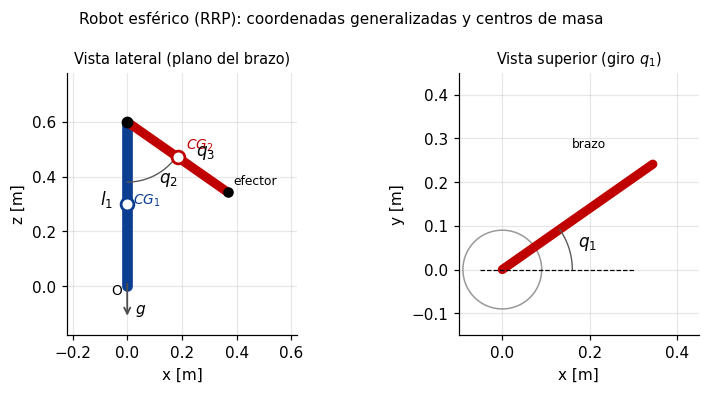

In [ ]:
COL = ["#0B3D91", "#C00000", "#2E8B57"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.6), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
q2d, q3v = 55.0, 0.45
q2r = np.deg2rad(q2d)
top = np.array([0.0, l1])
d = np.array([np.sin(q2r), -np.cos(q2r)])
ef = top + q3v*d
cg2 = top + 0.5*q3v*d
ax.plot([0, 0], [0, l1], lw=7, color=COL[0], solid_capstyle="round")
ax.plot([top[0], ef[0]], [top[1], ef[1]], lw=6, color=COL[1], solid_capstyle="round")
ax.scatter(0, l1/2, s=70, facecolor="w", edgecolor=COL[0], lw=1.8, zorder=6)
ax.scatter(*cg2, s=70, facecolor="w", edgecolor=COL[1], lw=1.8, zorder=6)
ax.scatter(*top, s=45, color="k", zorder=6)
ax.scatter(*ef, s=35, color="k", zorder=6)
ax.annotate(r"$CG_1$", (0.02, l1/2), fontsize=9, color=COL[0])
ax.annotate(r"$CG_2$", cg2 + np.array([0.03, 0.03]), fontsize=9, color=COL[1])
ax.annotate("efector", ef + np.array([0.02, 0.03]), fontsize=8)
ax.annotate("O", (-0.06, -0.03), fontsize=9)
ax.annotate(r"$l_1$", (-0.10, l1/2), fontsize=11)
ax.annotate(r"$q_3$", top + 0.55*q3v*d + np.array([0.05, 0.02]), fontsize=11)
th = np.linspace(-np.pi/2, -np.pi/2 + q2r, 60)
ax.plot(0.22*np.cos(th), l1 + 0.22*np.sin(th), color="0.35", lw=0.9)
ax.annotate(r"$q_2$", (0.25*np.sin(q2r/2), l1 - 0.25*np.cos(q2r/2)), fontsize=11)
ax.annotate("", xy=(0.0, -0.12), xytext=(0.0, 0.02), arrowprops=dict(arrowstyle="->", lw=1.2, color="0.3"))
ax.annotate("$g$", (0.03, -0.10), fontsize=10)
ax.set_aspect("equal"); ax.set_xlim(-0.22, 0.62); ax.set_ylim(-0.18, 0.78)
ax.set_xlabel("x [m]"); ax.set_ylabel("z [m]")
ax.set_title("Vista lateral (plano del brazo)", fontsize=9.5)
ax = axes[1]
cir = np.linspace(0, 2*np.pi, 200)
ax.plot(0.09*np.cos(cir), 0.09*np.sin(cir), color="0.6", lw=1)
ax.plot([0, 0.42*np.cos(np.deg2rad(35))], [0, 0.42*np.sin(np.deg2rad(35))], lw=6, color=COL[1], solid_capstyle="round")
ax.plot([-0.05, 0.30], [0, 0], "k--", lw=0.8)
arc = np.linspace(0, np.deg2rad(35), 60)
ax.plot(0.16*np.cos(arc), 0.16*np.sin(arc), color="0.35", lw=0.9)
ax.annotate(r"$q_1$", (0.18*np.cos(np.deg2rad(17)), 0.18*np.sin(np.deg2rad(17))), fontsize=11)
ax.annotate("brazo", (0.16, 0.28), fontsize=8)
ax.set_aspect("equal"); ax.set_xlim(-0.1, 0.45); ax.set_ylim(-0.15, 0.45)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Vista superior (giro $q_1$)", fontsize=9.5)
fig.suptitle("Robot esférico (RRP): coordenadas generalizadas y centros de masa", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/rrp_esquema.png"); plt.show()

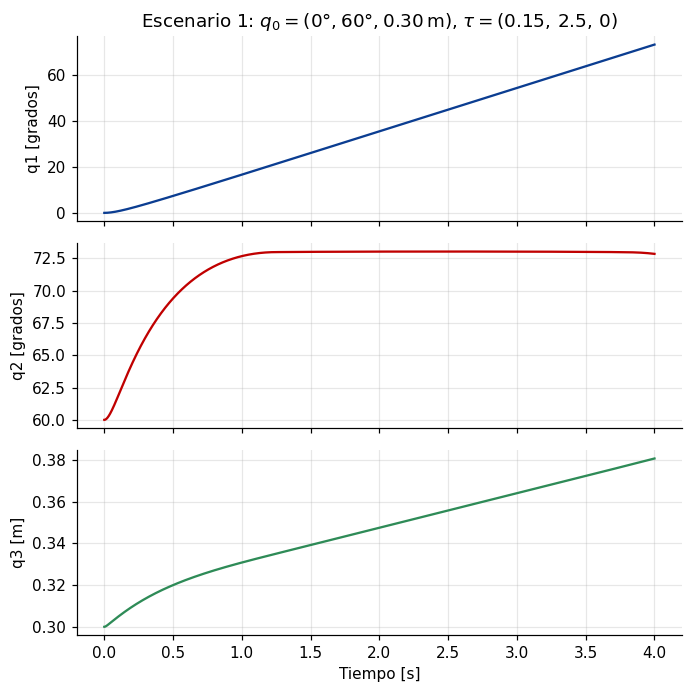

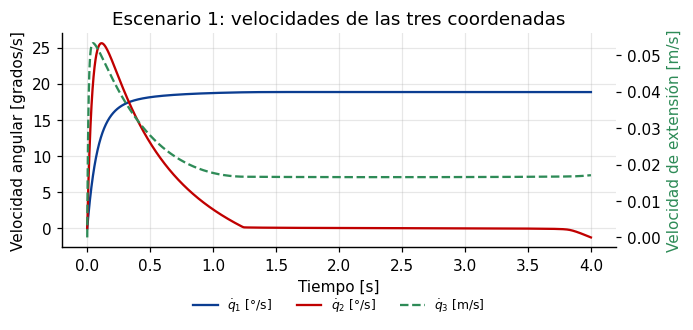

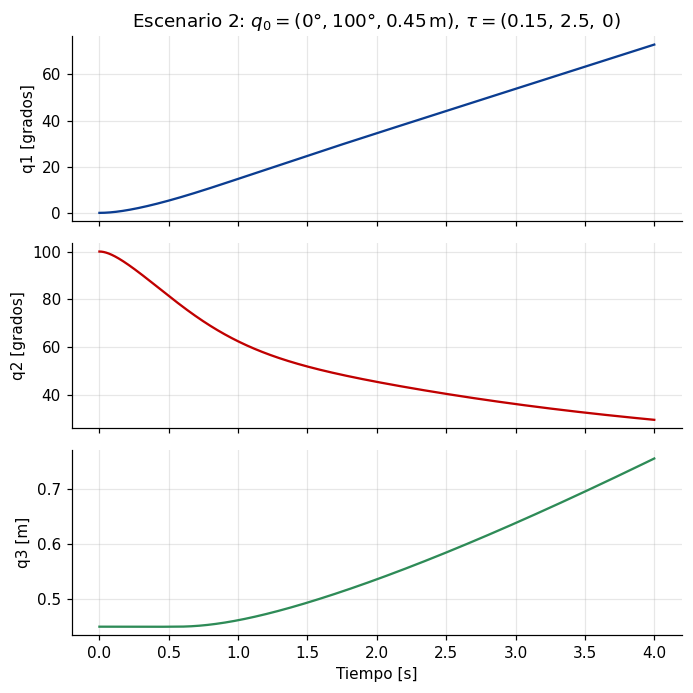

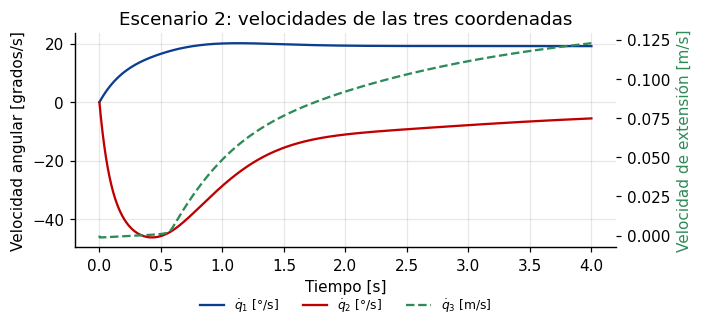

In [ ]:
def graf_q(sol, nombre, titulo):
    fig, ax = plt.subplots(3, 1, figsize=(6.4, 6.4), sharex=True)
    ax[0].plot(sol.t, np.rad2deg(sol.y[0]), color=COL[0]); ax[0].set_ylabel("q1 [grados]")
    ax[1].plot(sol.t, np.rad2deg(sol.y[1]), color=COL[1]); ax[1].set_ylabel("q2 [grados]")
    ax[2].plot(sol.t, sol.y[2], color=COL[2]); ax[2].set_ylabel("q3 [m]")
    ax[2].set_xlabel("Tiempo [s]"); ax[0].set_title(titulo)
    fig.tight_layout(); fig.savefig(f"{OUT}/{nombre}"); plt.show()

def graf_vel(sol, nombre, titulo):
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    ax.plot(sol.t, np.rad2deg(sol.y[3]), label=r"$\dot{q}_1$ [°/s]", color=COL[0])
    ax.plot(sol.t, np.rad2deg(sol.y[4]), label=r"$\dot{q}_2$ [°/s]", color=COL[1])
    ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("Velocidad angular [grados/s]")
    ax2 = ax.twinx()                                   # eje derecho para la velocidad de extensión
    ax2.plot(sol.t, sol.y[5], label=r"$\dot{q}_3$ [m/s]", color=COL[2], ls="--")
    ax2.set_ylabel("Velocidad de extensión [m/s]", color=COL[2]); ax2.grid(False)
    ax.set_title(titulo)
    h1, l1_ = ax.get_legend_handles_labels(); h2, l2_ = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1_ + l2_, ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    fig.tight_layout(); fig.savefig(f"{OUT}/{nombre}"); plt.show()

graf_q(e1, "rrp_e1_q.png", r"Escenario 1: $q_0=(0°,60°,0.30\,\mathrm{m})$, $\tau=(0.15,\,2.5,\,0)$")
graf_vel(e1, "rrp_e1_dq.png", "Escenario 1: velocidades de las tres coordenadas")
graf_q(e2, "rrp_e2_q.png", r"Escenario 2: $q_0=(0°,100°,0.45\,\mathrm{m})$, $\tau=(0.15,\,2.5,\,0)$")
graf_vel(e2, "rrp_e2_dq.png", "Escenario 2: velocidades de las tres coordenadas")

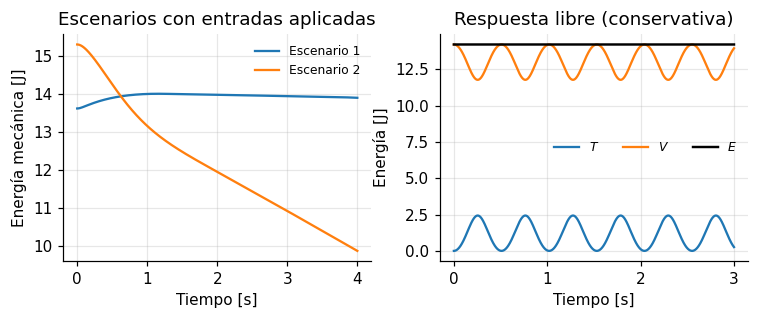

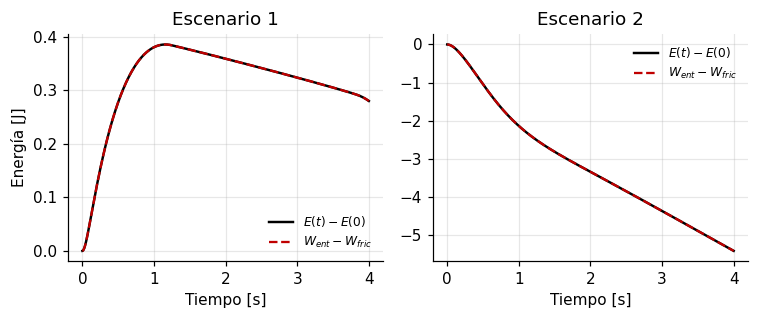

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(7.0, 3.0))
for sol, lab in ((e1, "Escenario 1"), (e2, "Escenario 2")):
    T, V = energia(sol.y)
    ax[0].plot(sol.t, T + V, label=lab)
ax[0].set_xlabel("Tiempo [s]"); ax[0].set_ylabel("Energía mecánica [J]")
ax[0].set_title("Escenarios con entradas aplicadas"); ax[0].legend(fontsize=8)
ax[1].plot(e3.t, T3, label="$T$"); ax[1].plot(e3.t, V3, label="$V$")
ax[1].plot(e3.t, E3, label="$E$", color="k", lw=1.6)
ax[1].set_xlabel("Tiempo [s]"); ax[1].set_ylabel("Energía [J]")
ax[1].set_title("Respuesta libre (conservativa)"); ax[1].legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/rrp_energia.png"); plt.show()

# Balance con entradas: E(t) - E(0) debe igualar  W_entradas - W_fricción
fig, ax = plt.subplots(1, 2, figsize=(7.0, 3.0))
for a, sol, tit in ((ax[0], e1, "Escenario 1"), (ax[1], e2, "Escenario 2")):
    T, V = energia(sol.y); E = T + V
    dq = sol.y[3:]
    W = np.array([np.dot(tau, sol.y[:3, k] - sol.y[:3, 0]) for k in range(len(sol.t))])
    pot = np.sum(friccion(dq.T, b_f, fc_f).T*dq, axis=0)
    D = np.concatenate([[0], np.cumsum(0.5*(pot[1:] + pot[:-1])*np.diff(sol.t))])
    a.plot(sol.t, E - E[0], label=r"$E(t)-E(0)$", color="k", lw=1.6)
    a.plot(sol.t, W - D, "--", label=r"$W_{ent}-W_{fric}$", color=COL[1])
    a.set_xlabel("Tiempo [s]"); a.set_title(tit); a.legend(fontsize=8)
ax[0].set_ylabel("Energía [J]")
fig.tight_layout(); fig.savefig(f"{OUT}/rrp_balance.png"); plt.show()

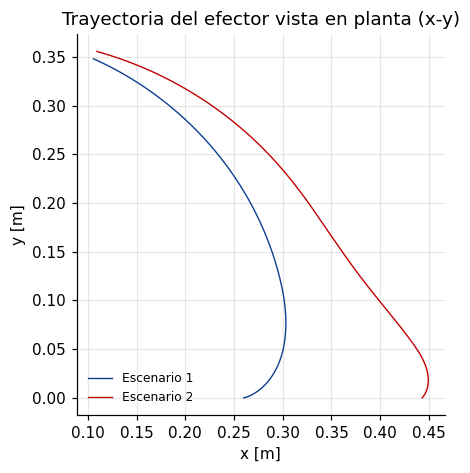

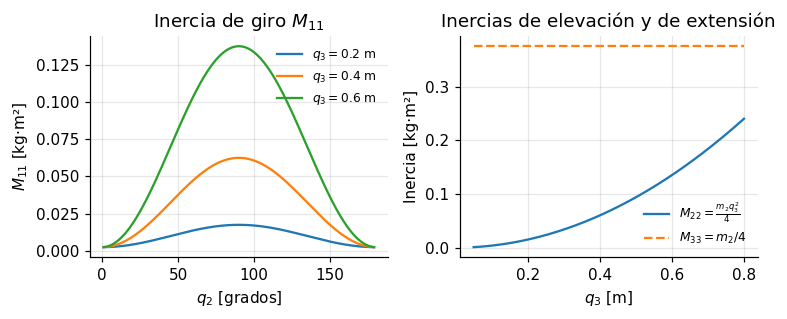

In [ ]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
for sol, lab, c in ((e1, "Escenario 1", COL[0]), (e2, "Escenario 2", COL[1])):
    x, y, z = efector(sol)
    ax.plot(x, y, lw=0.9, label=lab, color=c)
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Trayectoria del efector vista en planta (x-y)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(f"{OUT}/rrp_efector.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(7.0, 3.0))
q2v = np.linspace(1, 179, 400)
for q3v in (0.2, 0.4, 0.6):
    ax[0].plot(q2v, [matrices([0, np.deg2rad(a), q3v])[0][0, 0] for a in q2v], label=r"$q_3=%.1f$ m" % q3v)
ax[0].set_xlabel(r"$q_2$ [grados]"); ax[0].set_ylabel(r"$M_{11}$ [kg·m²]")
ax[0].set_title(r"Inercia de giro $M_{11}$"); ax[0].legend(fontsize=8)
q3v = np.linspace(0.05, 0.8, 300)
ax[1].plot(q3v, 0.25*m2*q3v**2, label=r"$M_{22}=\frac{m_2q_3^2}{4}$")
ax[1].plot(q3v, np.full_like(q3v, 0.25*m2), "--", label=r"$M_{33}=m_2/4$")
ax[1].set_xlabel(r"$q_3$ [m]"); ax[1].set_ylabel("Inercia [kg·m²]")
ax[1].set_title("Inercias de elevación y de extensión"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/rrp_inercia.png"); plt.show()